1. Upload & Import File

In [ ]:
# Import libraries
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, MinMaxScaler # Added MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Load data
df1 = pd.read_excel('/content/Master Data Dashboard.xlsx')
df2 = pd.read_excel('/content/Master Data Nita (2).xlsx')

2. Baca File Excel

In [ ]:
umkm_excel = pd.ExcelFile("Master Data Nita (2).xlsx")
pariwisata_excel = pd.ExcelFile("Master Data Dashboard.xlsx")

print("UMKM Sheets:", umkm_excel.sheet_names)
print("Pariwisata Sheets:", pariwisata_excel.sheet_names)

UMKM Sheets: ['Metadata', 'UMKM Per Provinsi', 'Pertumbuhan UMKM Pertahun', 'UMKM Per KabKota', 'Jumlah Tenaga Kerja UMKM', 'UMKM Berdasarkan Sektor']
Pariwisata Sheets: ['Metadata', 'Jumlah Pengunjung', 'Jumlah Hotel', 'Lama Menginap', 'Jumlah Kamar - Tempat Tidur Hot', 'PAD Pariwisata', 'IDM - Hotel', 'Jumlah Kawasan Pariwisata Berda', 'Jumlah Pengunjung Wisata Berdas', 'Jumlah Pengunjung Wisata Alam B', 'Jumlah Pendapatan Asli Daerah B', 'Jumlah Potensi Obyek Daya Tarik', 'Jumlah Tenaga Kerja ODTW']


3. Proses Sheet Jumlah Pengunjung

In [ ]:
pengunjung = pariwisata_excel.parse('Jumlah Pengunjung')
pengunjung = pengunjung[[
    'kode_kabupaten_kota', 'nama_kabupaten_kota', 'jenis_wisatawan',
    'pengunjung_akomodasi_wisata', 'tahun'
]]

pengunjung.dropna(subset=['pengunjung_akomodasi_wisata'], inplace=True)
pengunjung['pengunjung_akomodasi_wisata'] = pd.to_numeric(
    pengunjung['pengunjung_akomodasi_wisata'], errors='coerce')

# Pivot: Nusantara & Mancanegara jadi kolom
pengunjung_pivot = pengunjung.pivot_table(
    index=['kode_kabupaten_kota', 'nama_kabupaten_kota', 'tahun'],
    columns='jenis_wisatawan',
    values='pengunjung_akomodasi_wisata',
    aggfunc='sum'
).reset_index()

pengunjung_pivot.columns.name = None
pengunjung_pivot = pengunjung_pivot.rename(columns={
    'MANCANEGARA': 'pengunjung_mancanegara',
    'NUSANTARA': 'pengunjung_nusantara'
})

 4. Proses Sheet Jumlah Hotel

In [ ]:
hotel = pariwisata_excel.parse('Jumlah Hotel')
hotel = hotel[[
    'kode_kabupaten_kota', 'nama_kabupaten_kota', 'jumlah_hotel', 'tahun'
]]

hotel['jumlah_hotel'] = pd.to_numeric(hotel['jumlah_hotel'], errors='coerce')

# Total hotel per kab/kota/tahun
hotel_grouped = hotel.groupby(
    ['kode_kabupaten_kota', 'nama_kabupaten_kota', 'tahun'],
    as_index=False
)['jumlah_hotel'].sum()

5. Gabungkan Pengunjung + Hotel

In [ ]:
pariwisata_df = pd.merge(
    pengunjung_pivot, hotel_grouped,
    on=['kode_kabupaten_kota', 'nama_kabupaten_kota', 'tahun'],
    how='inner'
)

6. Proses Data UMKM

In [ ]:
umkm_df = umkm_excel.parse("UMKM Per KabKota")
umkm_df.columns

Index(['Kode_Kabupaten_Kota', 'Nama_Kabupaten_Kota', 'Tahun', 'Jumlah_UMKM',
       'Jumlah_Tenaga_Kerja_UMKM'],
      dtype='object')

In [ ]:
# Ubah semua kolom jadi lowercase dan hilangkan spasi
umkm_df.columns = umkm_df.columns.str.strip().str.lower()
pariwisata_df.columns = pariwisata_df.columns.str.strip().str.lower()

7. Gabungkan Data UMKM + Pariwisata

In [ ]:
full_df = pd.merge(
    pariwisata_df,
    umkm_df,
    on=['nama_kabupaten_kota', 'tahun'],
    how='inner'
)

In [ ]:
print("📌 Data gabungan UMKM + Pariwisata:")
full_df.head()

📌 Data gabungan UMKM + Pariwisata:


,kode_kabupaten_kota_x,nama_kabupaten_kota,tahun,pengunjung_mancanegara,pengunjung_nusantara,jumlah_hotel,kode_kabupaten_kota_y,jumlah_umkm,jumlah_tenaga_kerja_umkm
0,3201,KABUPATEN BOGOR,2019,0,0,318,3201,52640,52640
1,3201,KABUPATEN BOGOR,2020,0,0,318,3201,52852,111053
2,3201,KABUPATEN BOGOR,2021,0,4691066,101,3201,45013,124943
3,3201,KABUPATEN BOGOR,2022,31603,1737065,480,3201,43138,130541
4,3201,KABUPATEN BOGOR,2023,61481,3425508,118,3201,35524,84589


In [ ]:
# Definisikan periode
def assign_period(Tahun):
    if Tahun == 2019:
        return 'Pra-COVID'
    elif Tahun in [2020, 2021]:
        return 'Saat-COVID'
    else:  # 2022, 2023
        return 'Pasca-COVID'

full_df['periode'] = full_df['tahun'].apply(assign_period)

In [ ]:
full_df.head()

,kode_kabupaten_kota_x,nama_kabupaten_kota,tahun,pengunjung_mancanegara,pengunjung_nusantara,jumlah_hotel,kode_kabupaten_kota_y,jumlah_umkm,jumlah_tenaga_kerja_umkm,periode
0,3201,KABUPATEN BOGOR,2019,0,0,318,3201,52640,52640,Pra-COVID
1,3201,KABUPATEN BOGOR,2020,0,0,318,3201,52852,111053,Saat-COVID
2,3201,KABUPATEN BOGOR,2021,0,4691066,101,3201,45013,124943,Saat-COVID
3,3201,KABUPATEN BOGOR,2022,31603,1737065,480,3201,43138,130541,Pasca-COVID
4,3201,KABUPATEN BOGOR,2023,61481,3425508,118,3201,35524,84589,Pasca-COVID


In [ ]:
from sklearn.preprocessing import MinMaxScaler

# Pilih fitur numerik yang akan dianalisis
fitur_ml = full_df[[
    'pengunjung_mancanegara',
    'pengunjung_nusantara',
    'jumlah_hotel',
    'jumlah_umkm',
    'jumlah_tenaga_kerja_umkm'
]].copy()

# Simpan nama kabupaten dan tahun untuk referensi
info_daerah = full_df[['nama_kabupaten_kota', 'tahun']].reset_index(drop=True)

# Normalisasi
scaler = MinMaxScaler()
fitur_scaled = scaler.fit_transform(fitur_ml)

import numpy as np
fitur_scaled = pd.DataFrame(fitur_scaled, columns=fitur_ml.columns)

In [ ]:
print("📊 Hasil normalisasi fitur:")
pd.DataFrame(fitur_scaled, columns=fitur_ml.columns).head()

📊 Hasil normalisasi fitur:


,pengunjung_mancanegara,pengunjung_nusantara,jumlah_hotel,jumlah_umkm,jumlah_tenaga_kerja_umkm
0,0.000000,0.000000,0.479638,0.662849,0.237672
1,0.000000,0.000000,0.479638,0.665709,0.529193
2,0.000000,0.404595,0.152338,0.559958,0.598514
3,0.012915,0.149818,0.723982,0.534663,0.626452
4,0.025124,0.295443,0.177979,0.431948,0.397119


9. K-Means Clustering

Segmentasi Daerah

📈 Grafik Elbow Method membantu memilih jumlah cluster optimal.


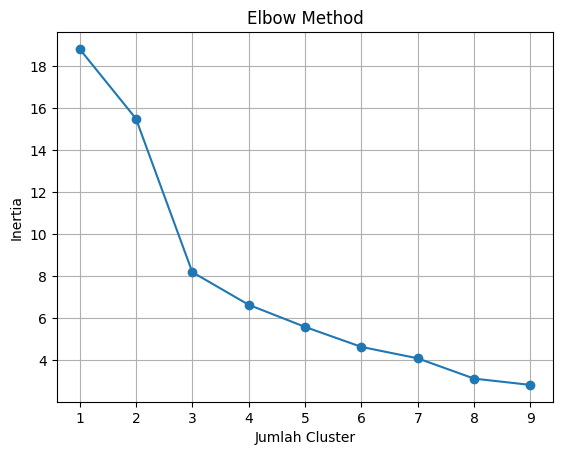

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Elbow Method untuk cari jumlah cluster optimal
inertia = []
for k in range(1, 10):
    km = KMeans(n_clusters=k, random_state=42)
    km.fit(fitur_scaled)
    inertia.append(km.inertia_)

print("📈 Grafik Elbow Method membantu memilih jumlah cluster optimal.")

# Plot Elbow
plt.plot(range(1, 10), inertia, marker='o')
plt.title('Elbow Method')
plt.xlabel('Jumlah Cluster')
plt.ylabel('Inertia')
plt.grid()
plt.show()

Jalankan Clustering Final

In [ ]:
k_optimal = 3  # angka sesuai hasil elbow
kmeans = KMeans(n_clusters=k_optimal, random_state=42)
full_df['cluster'] = kmeans.fit_predict(fitur_scaled)

In [ ]:
from sklearn.metrics import silhouette_score

# 1. Inertia (SSE)
sse = kmeans.inertia_
print(f"Inertia (SSE): {sse}")

# 2. Silhouette Score
silhouette_avg = silhouette_score(fitur_scaled, full_df['cluster'])
print(f"Silhouette Score: {silhouette_avg:.3f}")

Inertia (SSE): 8.184118453827892
Silhouette Score: 0.492


hasil clustering dievaluasi menggunakan Elbow dan Silhouette Score, hasil menunjukkan struktur cluster cukup baik dengan nilai 0.492

In [ ]:
# Urutkan cluster berdasarkan total skor indikator (UMKM, hotel, dll)
cluster_summary = full_df.groupby('cluster')[fitur_ml.columns.tolist()].mean()
cluster_summary['total'] = cluster_summary.sum(axis=1)

# Urutkan cluster dari rendah ke tinggi
cluster_sorted = cluster_summary.sort_values('total').reset_index()
cluster_sorted['cluster_fix'] = cluster_sorted.index

# Buat mapping cluster lama → cluster baru
mapping = dict(zip(cluster_sorted['cluster'], cluster_sorted['cluster_fix']))
label_mapping = {0: 'Rendah', 1: 'Sedang', 2: 'Tinggi'}

In [ ]:
# Terapkan ke full_df
full_df['cluster_fix'] = full_df['cluster'].map(mapping)
full_df['Kategori'] = full_df['cluster_fix'].map(label_mapping)

In [ ]:
# Lihat hasil akhir (cluster asli, fix, dan label)
full_df[['nama_kabupaten_kota', 'tahun', 'cluster', 'cluster_fix', 'Kategori', 'periode']].head(15)

,nama_kabupaten_kota,tahun,cluster,cluster_fix,Kategori,periode
0,KABUPATEN BOGOR,2019,1,1,Sedang,Pra-COVID
1,KABUPATEN BOGOR,2020,1,1,Sedang,Saat-COVID
2,KABUPATEN BOGOR,2021,1,1,Sedang,Saat-COVID
3,KABUPATEN BOGOR,2022,2,2,Tinggi,Pasca-COVID
4,KABUPATEN BOGOR,2023,1,1,Sedang,Pasca-COVID
5,KABUPATEN SUKABUMI,2019,1,1,Sedang,Pra-COVID
6,KABUPATEN SUKABUMI,2020,1,1,Sedang,Saat-COVID
7,KABUPATEN SUKABUMI,2021,1,1,Sedang,Saat-COVID
8,KABUPATEN SUKABUMI,2022,1,1,Sedang,Pasca-COVID
9,KABUPATEN SUKABUMI,2023,1,1,Sedang,Pasca-COVID


In [ ]:
full_df.head()

,kode_kabupaten_kota_x,nama_kabupaten_kota,tahun,pengunjung_mancanegara,pengunjung_nusantara,jumlah_hotel,kode_kabupaten_kota_y,jumlah_umkm,jumlah_tenaga_kerja_umkm,periode,cluster,cluster_fix,Kategori
0,3201,KABUPATEN BOGOR,2019,0,0,318,3201,52640,52640,Pra-COVID,1,1,Sedang
1,3201,KABUPATEN BOGOR,2020,0,0,318,3201,52852,111053,Saat-COVID,1,1,Sedang
2,3201,KABUPATEN BOGOR,2021,0,4691066,101,3201,45013,124943,Saat-COVID,1,1,Sedang
3,3201,KABUPATEN BOGOR,2022,31603,1737065,480,3201,43138,130541,Pasca-COVID,2,2,Tinggi
4,3201,KABUPATEN BOGOR,2023,61481,3425508,118,3201,35524,84589,Pasca-COVID,1,1,Sedang


## 10. Validasi Tambahan: Perbandingan Jumlah Cluster (k) dan Uji Stabilitas

Bagian ini menjawab masukan reviewer agar pemilihan k=3 tidak hanya didasarkan pada Elbow Method, tetapi juga divalidasi dengan Silhouette Score, Davies–Bouldin Index, dan Calinski–Harabasz Index untuk beberapa nilai k, serta diuji kestabilannya pada beberapa `random_state` dan `n_init`.

In [ ]:
from sklearn.metrics import davies_bouldin_score, calinski_harabasz_score

# 📊 Validasi jumlah cluster k=2..6
print("📊 Validasi k=2..6 (random_state=42, n_init=10):")
validasi_k = []
for k in range(2, 7):
    km_k = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_k = km_k.fit_predict(fitur_scaled)
    sil_k = silhouette_score(fitur_scaled, labels_k)
    db_k = davies_bouldin_score(fitur_scaled, labels_k)
    ch_k = calinski_harabasz_score(fitur_scaled, labels_k)
    validasi_k.append({
        'k': k,
        'inertia': km_k.inertia_,
        'silhouette': sil_k,
        'davies_bouldin': db_k,
        'calinski_harabasz': ch_k
    })
    print(f"k={k}: silhouette={sil_k:.4f}  davies_bouldin={db_k:.4f}  "
          f"calinski_harabasz={ch_k:.1f}  inertia={km_k.inertia_:.3f}")

validasi_k_df = pd.DataFrame(validasi_k)
validasi_k_df


**Interpretasi:** k=3 memiliki Davies–Bouldin Index terendah (terbaik) di antara k=2–5 dan Silhouette Score yang tinggi (mendekati k=2), sehingga hasil ini memperkuat pemilihan k=3 dari Elbow Method — bukan hanya berdasarkan penurunan inertia yang melandai, tetapi juga kekompakan/keterpisahan cluster.

In [ ]:
from sklearn.metrics import adjusted_rand_score

# 📊 Uji stabilitas k=3 pada beberapa random_state
print("📊 Stabilitas k=3 pada beberapa random_state:")
labelings = {}
for rs in [0, 1, 42, 123, 2024]:
    km_rs = KMeans(n_clusters=3, random_state=rs, n_init=10)
    labels_rs = km_rs.fit_predict(fitur_scaled)
    labelings[rs] = labels_rs
    sil_rs = silhouette_score(fitur_scaled, labels_rs)
    db_rs = davies_bouldin_score(fitur_scaled, labels_rs)
    print(f"random_state={rs}: silhouette={sil_rs:.4f}  davies_bouldin={db_rs:.4f}")

print("\n📊 Adjusted Rand Index antar-random_state (kestabilan partisi):")
rss = list(labelings.keys())
for i in range(len(rss)):
    for j in range(i + 1, len(rss)):
        ari = adjusted_rand_score(labelings[rss[i]], labelings[rss[j]])
        print(f"ARI(rs={rss[i]}, rs={rss[j]}) = {ari:.4f}")


In [ ]:
# 📊 Uji stabilitas k=3 pada beberapa n_init (random_state=42 tetap)
print("📊 Stabilitas k=3 pada beberapa n_init:")
for ninit in [1, 5, 10, 20, 50]:
    km_ni = KMeans(n_clusters=3, random_state=42, n_init=ninit)
    labels_ni = km_ni.fit_predict(fitur_scaled)
    sil_ni = silhouette_score(fitur_scaled, labels_ni)
    print(f"n_init={ninit}: silhouette={sil_ni:.4f}  inertia={km_ni.inertia_:.3f}")


**Interpretasi:** Adjusted Rand Index (ARI) antar-`random_state` berkisar 0,80–1,00, menunjukkan partisi klaster relatif stabil meskipun beberapa observasi pada batas antar-klaster — terutama anggota klaster Tinggi yang jumlahnya sedikit — berpotensi berpindah klaster pada inisialisasi acak yang berbeda. Hasil sepenuhnya konvergen (identik) untuk `n_init` ≥ 5, sehingga `n_init=10` (default lama scikit-learn) sudah cukup untuk hasil yang stabil.

## 11. Sentroid dalam Skala Ternormalisasi (0–1)

Tabel berikut melengkapi profil cluster pada skala asli (Bagian 5) dengan sentroid pada skala ternormalisasi 0–1 yang menjadi dasar perhitungan jarak K-Means, sesuai masukan reviewer.

In [ ]:
# 📊 Sentroid dalam skala ternormalisasi (0-1) per cluster_fix
fitur_scaled_labeled = fitur_scaled.copy()
fitur_scaled_labeled['cluster_fix'] = full_df['cluster_fix'].values
fitur_scaled_labeled['Kategori'] = full_df['Kategori'].values

centroid_ternormalisasi = fitur_scaled_labeled.groupby(['cluster_fix', 'Kategori'])[fitur_ml.columns.tolist()].mean()
print("📊 Sentroid ternormalisasi (0-1) per cluster:")
centroid_ternormalisasi.round(4)


## 12. Verifikasi Nilai Nol vs. Data Tidak Tersedia

Bagian ini menjawab masukan reviewer mengenai nilai nol pada Kabupaten Bogor (2019–2020) dan jumlah hotel Kota Banjar (2023), untuk membedakan nilai aktual dari kemungkinan data yang tidak dilaporkan pada sumber.

In [ ]:
# 🔍 Verifikasi nilai pengunjung Kabupaten Bogor 2019-2020 (raw source, sebelum merge)
cek_bogor = pengunjung[(pengunjung['kode_kabupaten_kota'] == 3201) & (pengunjung['tahun'].isin([2019, 2020]))]
print("🔍 Data mentah pengunjung Kabupaten Bogor 2019-2020 (sumber: sheet 'Jumlah Pengunjung'):")
print(cek_bogor[['nama_kabupaten_kota', 'jenis_wisatawan', 'pengunjung_akomodasi_wisata', 'tahun']])
print("\nCatatan: nilai 0 di atas tercatat literal pada sumber (bukan hasil merge/NaN yang terisi 0),")
print("namun kemungkinan tetap mencerminkan data yang tidak dilaporkan -- perlu dikonfirmasi ke sumber.")


In [ ]:
# 🔍 Verifikasi jumlah hotel Kota Banjar per kategori, 2019-2023 (raw source, sebelum agregasi)
cek_banjar = hotel[(hotel['kode_kabupaten_kota'] == 3279) & (hotel['tahun'].isin([2019, 2020, 2021, 2022, 2023]))].sort_values('tahun')
print("🔍 Data mentah jumlah hotel per kategori, Kota Banjar 2019-2023 (sumber: sheet 'Jumlah Hotel'):")
print(cek_banjar[['tahun', 'jumlah_hotel']])
print("\nCatatan: pada 2019-2022 selalu ada minimal satu kategori hotel bernilai > 0,")
print("sedangkan pada 2023 SELURUH kategori bernilai 0 -- indikasi kuat data tidak dilaporkan,")
print("bukan jumlah hotel yang benar-benar nol. Disarankan dikeluarkan atau diimputasi pada analisis lanjutan.")


## 13. Koreksi Angka Pengunjung Mancanegara Klaster Rendah Pasca-COVID

Draf laporan sebelumnya menyebut angka 1.869.686 untuk rata-rata pengunjung mancanegara klaster Rendah periode Pasca-COVID. Sel berikut menunjukkan nilai yang sebenarnya keluar dari kode, untuk menelusuri sumber kesalahan penulisan.

In [ ]:
# 🔍 Verifikasi angka pengunjung_mancanegara, cluster_fix=0 (Rendah), Pasca-COVID
subset_rendah_pasca = full_df[(full_df['cluster_fix'] == 0) & (full_df['periode'] == 'Pasca-COVID')]
rata2 = subset_rendah_pasca['pengunjung_mancanegara'].mean()
print(f"Rata-rata pengunjung_mancanegara (notasi biasa)   : {rata2:,.2f}")
print(f"Rata-rata pengunjung_mancanegara (notasi ilmiah)  : {rata2:.6e}")
print("\nAngka '1.869.686' pada draf sebelumnya adalah salah baca dari notasi ilmiah")
print("'1.869686e+04' (yang berarti 1,869686 x 10^4 = 18.696,86), bukan 1,87 juta.")


In [ ]:
# Simpan
full_df.to_csv("hasil_cluster_fix_per_periode.csv", index=False)

In [ ]:
from google.colab import files
files.download("hasil_cluster_fix_per_periode.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
period_order = ['Pra-COVID', 'Saat-COVID', 'Pasca-COVID']
full_df['periode'] = pd.Categorical(full_df['periode'], categories=period_order, ordered=True)
pivot = full_df.pivot_table(index='nama_kabupaten_kota', columns='periode', values='Kategori', aggfunc='first').reset_index()
pivot.to_csv("perbandingan_cluster_periode.csv", index=False)
pivot.head()

/tmp/ipykernel_650/2322882856.py:3: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot = full_df.pivot_table(index='nama_kabupaten_kota', columns='periode', values='Kategori', aggfunc='first').reset_index()


periode,nama_kabupaten_kota,Pra-COVID,Saat-COVID,Pasca-COVID
0,KABUPATEN BANDUNG,Sedang,Sedang,Sedang
1,KABUPATEN BANDUNG BARAT,Rendah,Rendah,Rendah
2,KABUPATEN BEKASI,Rendah,Rendah,Rendah
3,KABUPATEN BOGOR,Sedang,Sedang,Tinggi
4,KABUPATEN CIAMIS,Rendah,Rendah,Rendah


In [ ]:
from google.colab import files
files.download("perbandingan_cluster_periode.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Membandingkan nilai antara periode
changed_df = pivot[
    (pivot['Pra-COVID'] != pivot['Saat-COVID']) |
    (pivot['Saat-COVID'] != pivot['Pasca-COVID']) |
    (pivot['Pra-COVID'] != pivot['Pasca-COVID'])
]
# Menampilkan hasil
changed_df.to_csv("kabupaten_perubahan_periode.csv", index=False)
changed_df.head()

periode,nama_kabupaten_kota,Pra-COVID,Saat-COVID,Pasca-COVID
3,KABUPATEN BOGOR,Sedang,Sedang,Tinggi
11,KABUPATEN MAJALENGKA,Rendah,Sedang,Sedang
12,KABUPATEN PANGANDARAN,Rendah,Rendah,Sedang
26,KOTA TASIKMALAYA,Rendah,Sedang,Rendah


Rentang Nilai Setiap Variabel untuk Tiap Cluster:

In [ ]:
cluster_ranges = {}

for cluster in full_df['cluster_fix'].unique():
    cluster_data = full_df[full_df['cluster_fix'] == cluster]
    cluster_ranges[cluster] = {
        'jumlah_umkm': (
            cluster_data['jumlah_umkm'].min(),
            cluster_data['jumlah_umkm'].max()
        ),
        'jumlah_tenaga_kerja_umkm': (
            cluster_data['jumlah_tenaga_kerja_umkm'].min(),
            cluster_data['jumlah_tenaga_kerja_umkm'].max()
        ),
        'jumlah_hotel': (
            cluster_data['jumlah_hotel'].min(),
            cluster_data['jumlah_hotel'].max()
        ),
        'pengunjung_nusantara': (
            cluster_data['pengunjung_nusantara'].min(),
            cluster_data['pengunjung_nusantara'].max()
        ),
        'pengunjung_mancanegara': (
            cluster_data['pengunjung_mancanegara'].min(),
            cluster_data['pengunjung_mancanegara'].max()
        )
    }

In [ ]:
print("\n📊 Rentang Nilai Setiap Variabel untuk Tiap Cluster:")
for cluster, ranges in cluster_ranges.items():
    print(f"\nCluster {cluster} ({'Rendah' if cluster == 0 else 'Sedang' if cluster == 1 else 'Tinggi'}):")
    for index, value_range in ranges.items():
        print(f"  {index}: {value_range[0]:,.0f} - {value_range[1]:,.0f}")


📊 Rentang Nilai Setiap Variabel untuk Tiap Cluster:

Cluster 1 (Sedang):
  jumlah_umkm: 28,536 - 77,632
  jumlah_tenaga_kerja_umkm: 37,442 - 205,390
  jumlah_hotel: 0 - 354
  pengunjung_nusantara: 0 - 4,691,066
  pengunjung_mancanegara: 0 - 61,481

Cluster 2 (Tinggi):
  jumlah_umkm: 18,174 - 43,138
  jumlah_tenaga_kerja_umkm: 19,294 - 130,541
  jumlah_hotel: 170 - 663
  pengunjung_nusantara: 1,737,065 - 11,594,465
  pengunjung_mancanegara: 0 - 2,447,064

Cluster 0 (Rendah):
  jumlah_umkm: 3,505 - 33,101
  jumlah_tenaga_kerja_umkm: 5,017 - 67,066
  jumlah_hotel: 0 - 305
  pengunjung_nusantara: 0 - 4,960,343
  pengunjung_mancanegara: 0 - 244,109


Menghitung karakteristik dari setiap cluster

Visualisasi Cluster

In [ ]:
pip install geopy

In [ ]:
import pandas as pd
from geopy.geocoders import Nominatim
import time # Import time library

# Ganti dengan email kamu
geolocator = Nominatim(user_agent="nitasawalia71@gmail.com")

def get_coordinates(location):
    try: # Add try-except block to handle potential errors
        location = geolocator.geocode(location)
        if location:
            return location.latitude, location.longitude
        else:
            return None, None
    except Exception as e: # Catch any exceptions
        print(f"Error geocoding {location}: {e}")
        return None, None

# Membuat DataFrame baru hanya untuk kolom latitude dan longitude
lat_lon_df = pd.DataFrame()

# Menambahkan kolom latitude dan longitude ke DataFrame baru berdasarkan nama kabupaten/kota
# Add a small delay between requests
lat_lon_list = []
for location_name in full_df['nama_kabupaten_kota']:
    lat, lon = get_coordinates(location_name)
    lat_lon_list.append({'latitude': lat, 'longitude': lon})
    time.sleep(1) # Add a 1-second delay

lat_lon_df = pd.DataFrame(lat_lon_list)

# Menambahkan kolom latitude dan longitude ke full_df tanpa mengubah full_df yang asli
full_df = pd.concat([full_df, lat_lon_df], axis=1)

# Menyimpan ke file CSV
full_df.to_csv("kabupaten_koordinat.csv", index=False)

In [ ]:
print(full_df)

     kode_kabupaten_kota_x nama_kabupaten_kota  tahun  pengunjung_mancanegara  \
0                     3201     KABUPATEN BOGOR   2019                       0   
1                     3201     KABUPATEN BOGOR   2020                       0   
2                     3201     KABUPATEN BOGOR   2021                       0   
3                     3201     KABUPATEN BOGOR   2022                   31603   
4                     3201     KABUPATEN BOGOR   2023                   61481   
..                     ...                 ...    ...                     ...   
130                   3279         KOTA BANJAR   2019                      33   
131                   3279         KOTA BANJAR   2020                       9   
132                   3279         KOTA BANJAR   2021                       2   
133                   3279         KOTA BANJAR   2022                      16   
134                   3279         KOTA BANJAR   2023                      31   

     pengunjung_nusantara  

In [ ]:
print(full_df.columns)

Index(['kode_kabupaten_kota_x', 'nama_kabupaten_kota', 'tahun',
       'pengunjung_mancanegara', 'pengunjung_nusantara', 'jumlah_hotel',
       'kode_kabupaten_kota_y', 'jumlah_umkm', 'jumlah_tenaga_kerja_umkm',
       'periode', 'cluster', 'cluster_fix', 'Kategori', 'latitude',
       'longitude'],
      dtype='object')


In [ ]:
import folium

# Koordinat pusat Jawa Barat
latitude_jabar = -6.9637
longitude_jabar = 107.5773

# Membuat peta Jawa Barat
map_jabar = folium.Map(location=[latitude_jabar, longitude_jabar], zoom_start=8)  # Zoom level 8 untuk cakupan lebih luas

# Menambahkan marker dengan warna berdasarkan cluster
for idx, row in full_df.iterrows():
    color = 'red' if row['cluster'] == 0 else 'yellow' if row['cluster'] == 1 else 'green'
    folium.CircleMarker(location=[row['latitude'], row['longitude']],
                        radius=5, color=color, fill=True, fill_color=color).add_to(map_jabar)

# Menyimpan peta ke file HTML
map_jabar.save('cluster_map_jabar.html')

# Menampilkan peta interaktif
map_jabar

In [ ]:
import folium

# Fungsi untuk membuat peta berdasarkan nama periode
def generate_map_per_periode(periode, warna_cluster):
    m = folium.Map(location=[-6.9637, 107.5773], zoom_start=8)
    df_p = full_df[full_df['periode'] == periode]

    for _, row in df_p.iterrows():
        cluster = row['cluster_fix']
        color = warna_cluster.get(cluster, 'gray')
        folium.CircleMarker(
            location=[row['latitude'], row['longitude']],
            radius=6,
            color=color,
            fill=True,
            fill_color=color,
            popup=f"{row['nama_kabupaten_kota']} ({periode}) - Cluster {cluster}: {row['Kategori']}"
        ).add_to(m)

    filename = f"map_cluster_{periode.replace('-', '_')}.html"
    m.save(filename)
    print(f"✅ Map saved: {filename}")
    return m

# Warna per cluster
warna_cluster = {
    0: 'red',      # Rendah
    1: 'orange',   # Sedang
    2: 'green'     # Tinggi
}

# Buat 3 peta
map_pra     = generate_map_per_periode("Pra-COVID", warna_cluster)
map_saat    = generate_map_per_periode("Saat-COVID", warna_cluster)
map_pasca   = generate_map_per_periode("Pasca-COVID", warna_cluster)

# Tampilkan salah satu contoh (Pasca-COVID)
map_pra

✅ Map saved: map_cluster_Pra_COVID.html
✅ Map saved: map_cluster_Saat_COVID.html
✅ Map saved: map_cluster_Pasca_COVID.html


In [ ]:
map_saat

In [ ]:
map_pasca

In [ ]:
import folium

# Fungsi untuk membuat peta per tahun & langsung tampil di notebook
def generate_map_per_tahun(tahun, warna_cluster):
    m = folium.Map(location=[-6.9637, 107.5773], zoom_start=8)
    df_tahun = full_df[full_df['tahun'] == tahun]

    for _, row in df_tahun.iterrows():
        cluster = row['cluster_fix']
        color = warna_cluster.get(cluster, 'gray')
        folium.CircleMarker(
            location=[row['latitude'], row['longitude']],
            radius=6,
            color=color,
            fill=True,
            fill_color=color,
            popup=f"{row['nama_kabupaten_kota']} ({tahun}) - Cluster {cluster}: {row['Kategori']}"
        ).add_to(m)

    print(f"✅ Map displayed for: {tahun}")
    return m

# Warna per cluster
warna_cluster = {
    0: 'red',      # Rendah
    1: 'orange',   # Sedang
    2: 'green'     # Tinggi
}

# Contoh: Tampilkan peta untuk semua tahun satu per satu
maps_per_tahun = {}
for tahun in sorted(full_df['tahun'].unique()):
    maps_per_tahun[tahun] = generate_map_per_tahun(tahun, warna_cluster)

# Misal: tampilkan salah satu map (contoh tahun 2020)
maps_per_tahun[2019]


✅ Map displayed for: 2019
✅ Map displayed for: 2020
✅ Map displayed for: 2021
✅ Map displayed for: 2022
✅ Map displayed for: 2023


In [ ]:
maps_per_tahun[2020]

In [ ]:
maps_per_tahun[2021]

In [ ]:
maps_per_tahun[2022]

In [ ]:
maps_per_tahun[2023]

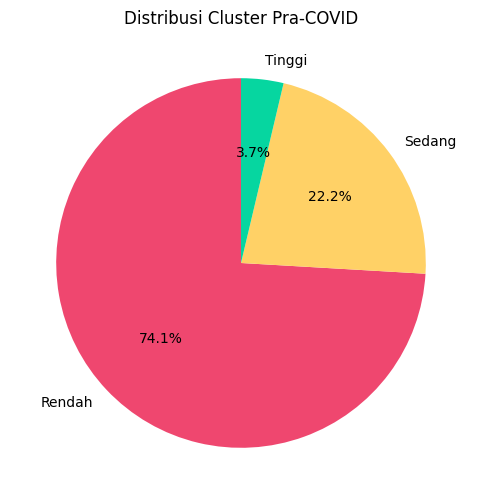

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Pie chart untuk distribusi cluster Pra-COVID
plt.figure(figsize=(6, 6))
full_df[full_df['periode'] == 'Pra-COVID']['Kategori'].value_counts().plot.pie(
    autopct='%1.1f%%', colors=['#ef476f', '#ffd166', '#06d6a0'], startangle=90
)
plt.title('Distribusi Cluster Pra-COVID')
plt.ylabel('')
plt.show()

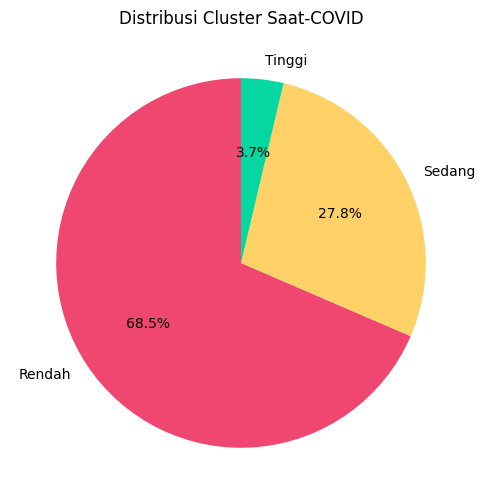

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Pie chart untuk distribusi cluster Saat-COVID
plt.figure(figsize=(6, 6))
full_df[full_df['periode'] == 'Saat-COVID']['Kategori'].value_counts().plot.pie(
    autopct='%1.1f%%', colors=['#ef476f', '#ffd166', '#06d6a0'], startangle=90
)
plt.title('Distribusi Cluster Saat-COVID')
plt.ylabel('')
plt.show()

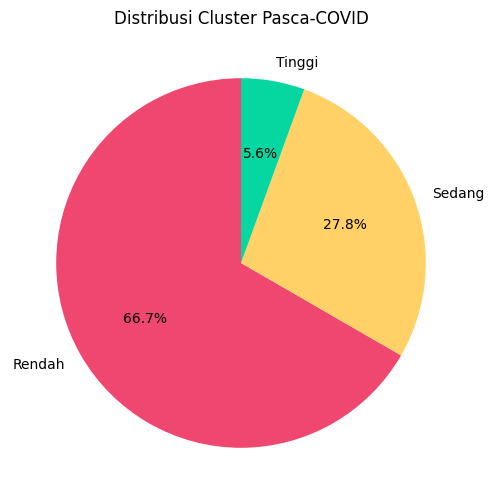

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Pie chart untuk distribusi cluster pasca-COVID
plt.figure(figsize=(6, 6))
full_df[full_df['periode'] == 'Pasca-COVID']['Kategori'].value_counts().plot.pie(
    autopct='%1.1f%%', colors=['#ef476f', '#ffd166', '#06d6a0'], startangle=90
)
plt.title('Distribusi Cluster Pasca-COVID')
plt.ylabel('')
plt.show()

Bar Chart Jumlah Daerah per Cluster (per Periode)

/tmp/ipykernel_650/3680961.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


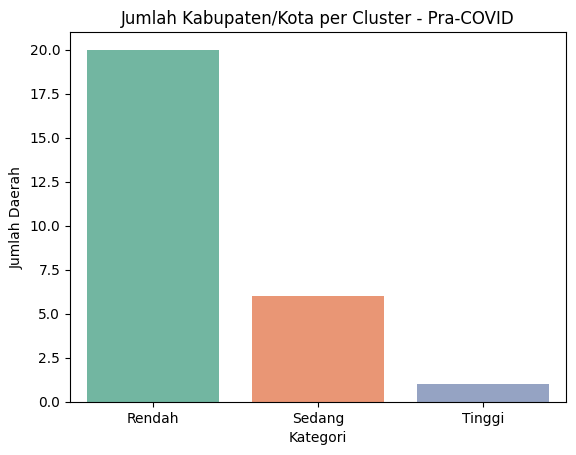

In [ ]:
sns.countplot(
    data=full_df[full_df['periode'] == 'Pra-COVID'],
    x='Kategori',
    order=['Rendah', 'Sedang', 'Tinggi'],
    palette='Set2'
)
plt.title('Jumlah Kabupaten/Kota per Cluster - Pra-COVID')
plt.xlabel('Kategori')
plt.ylabel('Jumlah Daerah')
plt.show()

/tmp/ipykernel_650/1072907050.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


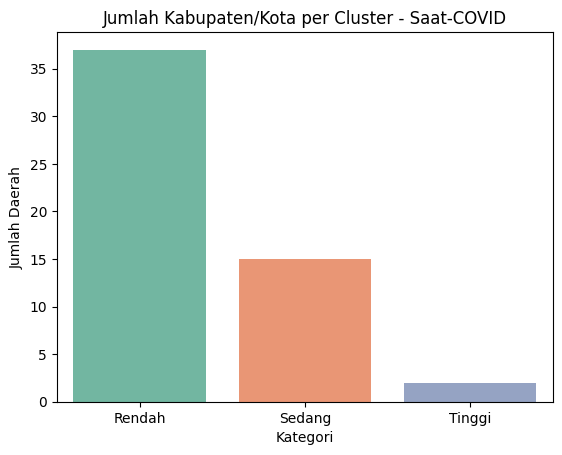

In [ ]:
sns.countplot(
    data=full_df[full_df['periode'] == 'Saat-COVID'],
    x='Kategori',
    order=['Rendah', 'Sedang', 'Tinggi'],
    palette='Set2'
)
plt.title('Jumlah Kabupaten/Kota per Cluster - Saat-COVID')
plt.xlabel('Kategori')
plt.ylabel('Jumlah Daerah')
plt.show()

/tmp/ipykernel_650/1688331538.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


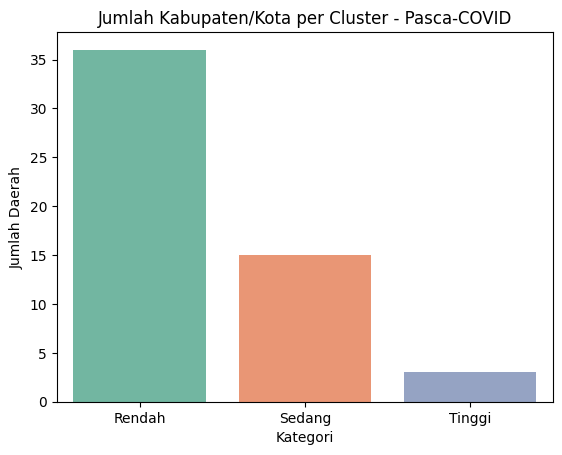

In [ ]:
sns.countplot(
    data=full_df[full_df['periode'] == 'Pasca-COVID'],
    x='Kategori',
    order=['Rendah', 'Sedang', 'Tinggi'],
    palette='Set2'
)
plt.title('Jumlah Kabupaten/Kota per Cluster - Pasca-COVID')
plt.xlabel('Kategori')
plt.ylabel('Jumlah Daerah')
plt.show()

/tmp/ipykernel_650/559482897.py:2: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot_cluster = full_df.pivot_table(


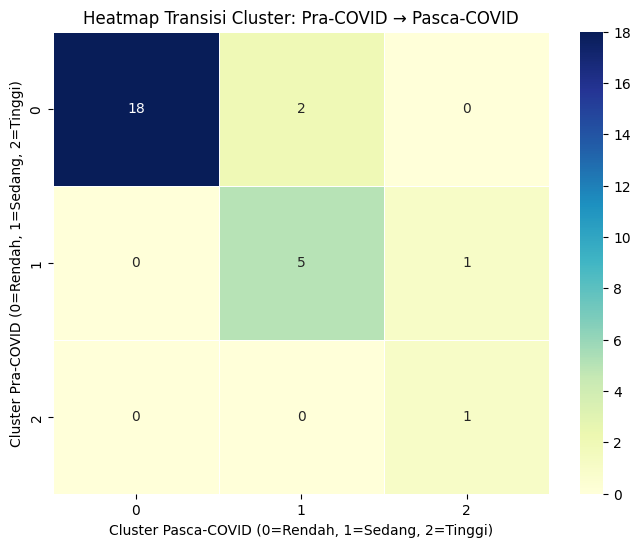

In [ ]:
# Buat pivot untuk transisi cluster antar periode
pivot_cluster = full_df.pivot_table(
    index='nama_kabupaten_kota',
    columns='periode',
    values='cluster_fix',
    aggfunc='first'
)

# Crosstab transisi Pra-COVID ke Pasca-COVID
transitions = pd.crosstab(
    pivot_cluster['Pra-COVID'],
    pivot_cluster['Pasca-COVID']
)

# Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(transitions, annot=True, fmt='d', cmap='YlGnBu', linewidths=.5)
plt.title("Heatmap Transisi Cluster: Pra-COVID → Pasca-COVID")
plt.xlabel("Cluster Pasca-COVID (0=Rendah, 1=Sedang, 2=Tinggi)")
plt.ylabel("Cluster Pra-COVID (0=Rendah, 1=Sedang, 2=Tinggi)")
plt.show()

Hasil Clustering untuk Mengelompokkan daerah berdasarkan kekuatan sektor

In [ ]:
full_df.to_csv("hasil_cluster_rf.csv", index=False)

In [ ]:
from google.colab import files
files.download("hasil_cluster_rf.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Buat Tabel Rata-rata Fitur per Cluster (di Python)

In [ ]:
fitur_mean_per_periode = full_df.groupby(['periode', 'cluster_fix'])[
    ['jumlah_umkm', 'jumlah_tenaga_kerja_umkm', 'jumlah_hotel',
     'pengunjung_nusantara', 'pengunjung_mancanegara']
].mean().round(0).reset_index()
fitur_mean_per_periode

/tmp/ipykernel_650/958125779.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  fitur_mean_per_periode = full_df.groupby(['periode', 'cluster_fix'])[


,periode,cluster_fix,jumlah_umkm,jumlah_tenaga_kerja_umkm,jumlah_hotel,pengunjung_nusantara,pengunjung_mancanegara
0,Pra-COVID,0,15767.0,15767.0,45.0,530061.0,27209.0
1,Pra-COVID,1,49160.0,49160.0,164.0,219486.0,18468.0
2,Pra-COVID,2,19294.0,19294.0,663.0,5964000.0,2447064.0
3,Saat-COVID,0,14357.0,31929.0,61.0,429419.0,9959.0
4,Saat-COVID,1,45093.0,97992.0,110.0,529577.0,1463.0
5,Saat-COVID,2,20283.0,57675.0,532.0,3968799.0,816894.0
6,Pasca-COVID,0,15129.0,34989.0,36.0,615164.0,18697.0
7,Pasca-COVID,1,44362.0,102128.0,72.0,754021.0,8128.0
8,Pasca-COVID,2,33123.0,101685.0,354.0,5785871.0,12536.0


In [ ]:
# Ambil hanya kolom numerik penting + cluster
fitur_mean = full_df.groupby('cluster')[[
    'jumlah_umkm',
    'jumlah_tenaga_kerja_umkm',
    'jumlah_hotel',
    'pengunjung_nusantara',
    'pengunjung_mancanegara'
]].mean().round(0).reset_index()

fitur_mean

,cluster,jumlah_umkm,jumlah_tenaga_kerja_umkm,jumlah_hotel,pengunjung_nusantara,pengunjung_mancanegara
0,0,14959.0,29638.0,48.0,522964.0,17051.0
1,1,45466.0,91577.0,103.0,571413.0,7074.0
2,2,26538.0,73283.0,465.0,5209869.0,686410.0


In [ ]:
full_df.to_csv("fitur_mean.csv", index=False)

In [ ]:
from google.colab import files
files.download("fitur_mean.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
fitur_mean_all_years = full_df[[
    'jumlah_umkm',
    'jumlah_tenaga_kerja_umkm',
    'jumlah_hotel',
    'pengunjung_nusantara',
    'pengunjung_mancanegara'
]].mean().round(0)

print(fitur_mean_all_years)

jumlah_umkm                  23609.0
jumlah_tenaga_kerja_umkm     48095.0
jumlah_hotel                    81.0
pengunjung_nusantara        744190.0
pengunjung_mancanegara       44140.0
dtype: float64


Menambahkan analisis perubahan berdasarkan periode

In [ ]:
# Analisis perubahan variabel pada setiap periode
period_change = full_df.groupby(['periode', 'cluster_fix']).agg({
    'jumlah_umkm': 'mean',
    'pengunjung_mancanegara': 'mean',
    'pengunjung_nusantara': 'mean',
    'jumlah_hotel': 'mean'
}).reset_index()

# Menampilkan hasil perubahan
print(period_change)

       periode  cluster_fix   jumlah_umkm  pengunjung_mancanegara  \
0    Pra-COVID            0  15767.150000            2.720940e+04   
1    Pra-COVID            1  49160.000000            1.846817e+04   
2    Pra-COVID            2  19294.000000            2.447064e+06   
3   Saat-COVID            0  14357.000000            9.958946e+03   
4   Saat-COVID            1  45092.866667            1.462667e+03   
5   Saat-COVID            2  20283.000000            8.168940e+05   
6  Pasca-COVID            0  15128.694444            1.869686e+04   
7  Pasca-COVID            1  44362.066667            8.127733e+03   
8  Pasca-COVID            2  33123.333333            1.253567e+04   

   pengunjung_nusantara  jumlah_hotel  
0          5.300608e+05     45.150000  
1          2.194857e+05    163.833333  
2          5.964000e+06    663.000000  
3          4.294186e+05     61.189189  
4          5.295767e+05    109.866667  
5          3.968799e+06    532.500000  
6          6.151642e+05     3

/tmp/ipykernel_650/3458870818.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  period_change = full_df.groupby(['periode', 'cluster_fix']).agg({


Menyimpulkan perubahan berdasarkan variabel tertentu

In [ ]:
# Perubahan jumlah UMKM dan pengunjung saat COVID
covid_analysis = full_df[full_df['periode'] == 'Saat-COVID'].groupby('cluster_fix').agg({
    'jumlah_umkm': 'mean',
    'pengunjung_mancanegara': 'mean',
    'pengunjung_nusantara': 'mean'
}).reset_index()

print(covid_analysis)

   cluster_fix   jumlah_umkm  pengunjung_mancanegara  pengunjung_nusantara
0            0  14357.000000             9958.945946          4.294186e+05
1            1  45092.866667             1462.666667          5.295767e+05
2            2  20283.000000           816894.000000          3.968799e+06


In [ ]:
# Mengelompokkan berdasarkan periode dan cluster
kabupaten_per_periode = full_df.groupby(['periode', 'cluster_fix'])[['jumlah_umkm', 'jumlah_tenaga_kerja_umkm', 'jumlah_hotel', 'pengunjung_mancanegara', 'pengunjung_nusantara']].mean()

# Menampilkan hasilnya untuk melihat bagaimana tiap kabupaten/kota berperforma selama periode yang berbeda
print(kabupaten_per_periode)

                          jumlah_umkm  jumlah_tenaga_kerja_umkm  jumlah_hotel  \
periode     cluster_fix                                                         
Pra-COVID   0            15767.150000              15767.150000     45.150000   
            1            49160.000000              49160.000000    163.833333   
            2            19294.000000              19294.000000    663.000000   
Saat-COVID  0            14357.000000              31929.378378     61.189189   
            1            45092.866667              97992.066667    109.866667   
            2            20283.000000              57675.000000    532.500000   
Pasca-COVID 0            15128.694444              34988.972222     36.055556   
            1            44362.066667             102128.000000     71.800000   
            2            33123.333333             101685.333333    354.000000   

                         pengunjung_mancanegara  pengunjung_nusantara  
periode     cluster_fix             

/tmp/ipykernel_650/3615905762.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  kabupaten_per_periode = full_df.groupby(['periode', 'cluster_fix'])[['jumlah_umkm', 'jumlah_tenaga_kerja_umkm', 'jumlah_hotel', 'pengunjung_mancanegara', 'pengunjung_nusantara']].mean()


In [ ]:
from IPython.display import IFrame

# Replace 'map_cluster_2019.html' with the actual filename you want to display
IFrame('map_cluster_2019.html', width=800, height=600)